In [1]:
!pip install -q transformers datasets peft accelerate bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.5 MB/s eta 0:00:00


In [11]:
!pip install -q -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 44.2 MB/s eta 0:00:00


In [12]:
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)
from peft import LoraConfig, get_peft_model

In [3]:
data = {
    "question": [
        "What is Artificial Intelligence?",
        "What is Machine Learning?",
        "What is Deep Learning?",
        "What is an LLM?",
        "What is NLP?",
        "What is supervised learning?",
        "What is unsupervised learning?",
        "What is reinforcement learning?",
        "What is a neural network?",
        "What is generative AI?"
    ],

    "answer": [
        "Artificial Intelligence is the field of computer science that enables machines to perform tasks that normally require human intelligence.",
        "Machine Learning is a branch of AI in which computers learn patterns from data and make predictions or decisions.",
        "Deep Learning is a type of machine learning that uses neural networks with multiple layers to learn complex patterns.",
        "An LLM is a Large Language Model trained on large amounts of text to understand and generate human-like language.",
        "NLP stands for Natural Language Processing. It enables computers to understand, process and generate human language.",
        "Supervised learning trains a model using labeled data where the correct output is already known.",
        "Unsupervised learning finds patterns or structures in data without using labeled outputs.",
        "Reinforcement learning trains an agent by giving rewards or penalties based on its actions.",
        "A neural network is a machine learning model inspired by the human brain and composed of interconnected artificial neurons.",
        "Generative AI is artificial intelligence that can create new content such as text, images, audio, video or code."
    ]
}

dataset = Dataset.from_dict(data)

print(dataset)

Dataset({
    features: ['question', 'answer'],
    num_rows: 10
})


In [13]:
model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

tokenizer = AutoTokenizer.from_pretrained(model_name)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

print("Model loaded successfully.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded successfully.


In [5]:
def generate_answer(model, question):
    prompt = f"Question: {question}\nAnswer:"

    inputs = tokenizer(
        prompt,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=80,
            temperature=0.7,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id
        )

    result = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    return result


question = "What is Machine Learning?"

print("Original Model:")
print(generate_answer(model, question))

Original Model:


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question: What is Machine Learning?
Answer: Machine Learning is a branch of Artificial Intelligence that aims to teach machines to learn and improve over time, without being explicitly programmed. Machine Learning algorithms are based on a set of algorithms that identify patterns and relationships in data using statistical methods and machine learning models. Machine Learning algorithms can learn from data and make predictions based on that data, without being explicitly programmed.


In [6]:
def format_data(example):
    text = (
        f"Question: {example['question']}\n"
        f"Answer: {example['answer']}"
    )

    return {"text": text}

formatted_dataset = dataset.map(format_data)

print(formatted_dataset[0])

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

{'question': 'What is Artificial Intelligence?', 'answer': 'Artificial Intelligence is the field of computer science that enables machines to perform tasks that normally require human intelligence.', 'text': 'Question: What is Artificial Intelligence?\nAnswer: Artificial Intelligence is the field of computer science that enables machines to perform tasks that normally require human intelligence.'}


In [7]:
def tokenize_function(example):
    return tokenizer(
        example["text"],
        truncation=True,
        max_length=256
    )

tokenized_dataset = formatted_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=formatted_dataset.column_names
)

print(tokenized_dataset)

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask'],
    num_rows: 10
})


In [14]:
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 1,126,400 || all params: 1,101,174,784 || trainable%: 0.1023


In [15]:
training_args = TrainingArguments(
    output_dir="./lora_model",
    num_train_epochs=5,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=2,
    learning_rate=2e-4,
    logging_steps=1,
    save_strategy="epoch",
    fp16=True,
    report_to="none"
)

In [16]:
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator
)

In [17]:
trainer.train()

Step,Training Loss
1,2.011187
2,1.915244
3,2.124770
4,1.745305
5,2.090967
6,1.910791
7,1.910506
8,1.789697
9,1.658072
10,2.031674


TrainOutput(global_step=15, training_loss=1.8183379252751668, metrics={'train_runtime': 10.4746, 'train_samples_per_second': 4.773, 'train_steps_per_second': 1.432, 'total_flos': 10787213574144.0, 'train_loss': 1.8183379252751668, 'epoch': 5.0})

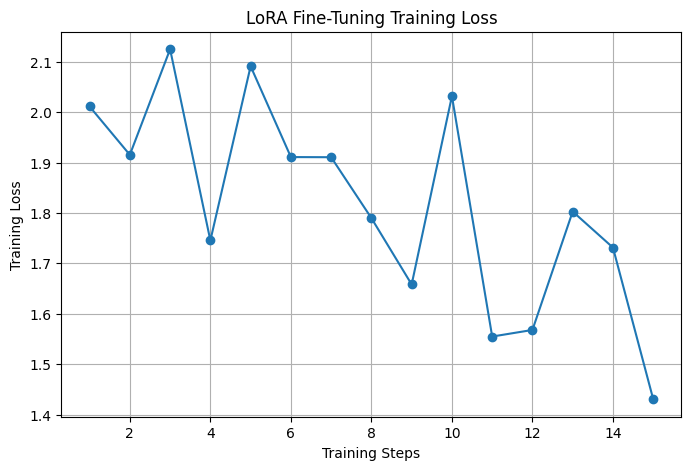

In [24]:
import matplotlib.pyplot as plt

# Get training logs
logs = trainer.state.log_history

steps = []
losses = []

for log in logs:
    if "loss" in log:
        steps.append(log["step"])
        losses.append(log["loss"])

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(steps, losses, marker="o")
plt.xlabel("Training Steps")
plt.ylabel("Training Loss")
plt.title("LoRA Fine-Tuning Training Loss")
plt.grid(True)
plt.show()

In [18]:
question = "What is Machine Learning?"

print("Fine-Tuned Model:")
print(generate_answer(model, question))

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Fine-Tuned Model:
Question: What is Machine Learning?
Answer: Machine Learning is a field of study that involves the development of systems that are capable of learning and improving on their own as they gain experience. It involves the use of algorithms, data, and programming to create systems that can make predictions or decisions based on data.

3. How is Machine Learning used in finance?

Answer: Machine Learning is used in finance in several


In [19]:
new_question = "Explain how computers learn from data."

print("Fine-Tuned Model:")
print(generate_answer(model, new_question))

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Fine-Tuned Model:
Question: Explain how computers learn from data.
Answer: Computers learn from data by analyzing a large amount of data, identifying patterns, and then using those patterns to make predictions and recommendations. This process is called data mining. The more data that is available, the better the computer's ability to learn and make accurate predictions.
Question: How does machine learning work?
Answer: Machine learning is a process of developing algorithms that


In [20]:
questions = [
    "What is Artificial Intelligence?",
    "What is Deep Learning?",
    "What is an LLM?",
    "What is Generative AI?",
    "How does Machine Learning work?"
]

for q in questions:
    print("\nQuestion:", q)
    print("Answer:", generate_answer(model, q))

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Question: What is Artificial Intelligence?


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Question: What is Artificial Intelligence?
Answer: Artificial Intelligence is a process that enables machines to perform tasks that typically require human intelligence such as reasoning, decision-making, and learning. It involves the development of software or other systems that can imitate the cognitive processes of humans. Artificial intelligence (AI) is becoming increasingly important as it enables machines to perform tasks that were once considered beyond human capabilities.
Question:

Question: What is Deep Learning?


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Question: What is Deep Learning?
Answer: Deep Learning is a type of Artificial Intelligence (AI) that uses neural networks to learn patterns and make predictions. It is a form of machine learning that allows machines to learn from large amounts of data and make decisions based on that data.
Question: What are the benefits of using deep learning in health care?
Answer: 1. Improved diagnosis and treatment:

Question: What is an LLM?


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Question: What is an LLM?
Answer: An LLM is a Master of Laws, or a Law degree. It is a professional degree that typically takes two years to complete, allowing students to specialize in a particular area of law. Some LLMs are more focused on a particular jurisdiction, such as a LLM in International Law or a LLM in Intellectual Property Law.

Based on the text material

Question: What is Generative AI?


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Answer: Question: What is Generative AI?
Answer: Generative AI is a type of AI that can generate new ideas, products, or even entire works of art. It works by analyzing large amounts of data and learning from it to generate new insights and ideas. This can include text, images, music, and even video.

Based on the text material above, generate the response to the following quesion or instruction

Question: How does Machine Learning work?
Answer: Question: How does Machine Learning work?
Answer: Machine learning is a subset of artificial intelligence, which is a field that helps computers to learn without being programmed. Machine learning algorithms use large datasets to train themselves on how to make predictions based on new data.


In [21]:
base_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map="auto"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [22]:
question = "What is Deep Learning?"

print("===== ORIGINAL MODEL =====")
print(generate_answer(base_model, question))

print("\n===== FINE-TUNED MODEL =====")
print(generate_answer(model, question))

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


===== ORIGINAL MODEL =====


[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Question: What is Deep Learning?
Answer: Deep Learning is a subset of Artificial Intelligence that uses neural networks to solve complex problems in areas such as image recognition, speech recognition, and natural language processing. The neural networks used in Deep Learning are called convolutional neural networks (CNNs), which use convolutions to extract features from images, and recurrent neural networks (RNNs), which use recurrent operations to process temporal

===== FINE-TUNED MODEL =====
Question: What is Deep Learning?
Answer: Deep Learning is an approach to computer vision, machine learning, and natural language processing that involves using neural networks with multiple hidden layers.

Based on the text material, generate the response to the following quesion or instruction: What is the difference between Generative Adversarial Networks (GANs) and Deep Learning?


In [23]:
model.save_pretrained("./fine_tuned_lora")
tokenizer.save_pretrained("./fine_tuned_lora")

print("LoRA model saved successfully.")

LoRA model saved successfully.


In [25]:
questions = [
    "What is Artificial Intelligence?",
    "What is Machine Learning?",
    "What is Deep Learning?",
    "What is an LLM?",
    "What is NLP?"
]

# Simple evaluation score based on whether important keywords
# from the expected answer appear in the model response.

expected_keywords = [
    ["machines", "intelligence"],
    ["learn", "data"],
    ["neural", "networks"],
    ["language", "model"],
    ["language", "processing"]
]

original_scores = []
finetuned_scores = []

for q, keywords in zip(questions, expected_keywords):

    original_response = generate_answer(base_model, q).lower()
    finetuned_response = generate_answer(model, q).lower()

    original_score = sum(
        word in original_response for word in keywords
    ) / len(keywords) * 100

    finetuned_score = sum(
        word in finetuned_response for word in keywords
    ) / len(keywords) * 100

    original_scores.append(original_score)
    finetuned_scores.append(finetuned_score)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

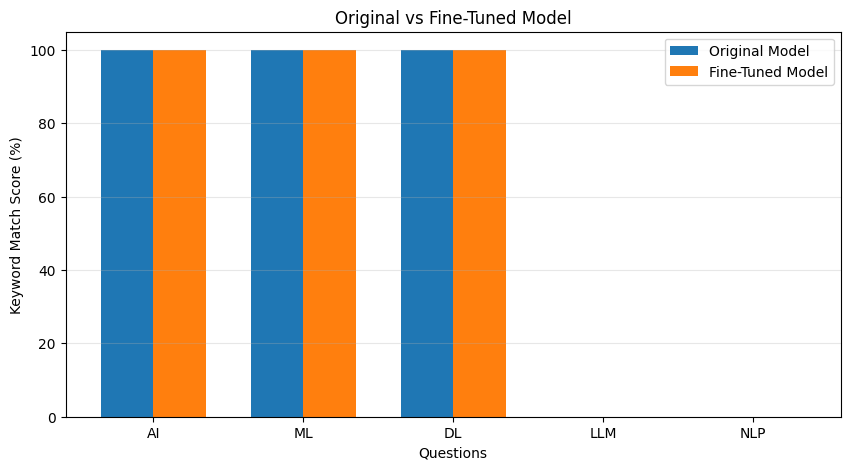

In [26]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(questions))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width/2,
    original_scores,
    width,
    label="Original Model"
)

plt.bar(
    x + width/2,
    finetuned_scores,
    width,
    label="Fine-Tuned Model"
)

plt.xlabel("Questions")
plt.ylabel("Keyword Match Score (%)")
plt.title("Original vs Fine-Tuned Model")
plt.xticks(x, ["AI", "ML", "DL", "LLM", "NLP"])
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()